## ** User Request **

"hello, I am trying to start a project about air quality in chicago using open source data from this api link:

https://dev.socrata.com/foundry/data.cityofchicago.org/xfya-dxtq 

I would like to start by loading in the data and then displaying the head of the data set. Then making a map with all the sensors and allow you to interact/click on the sensor and gain more information.

The following steps would be to create a network analysis and then I would like to create a spatial temporal graph neural network like the one seen here:
https://github.com/TorchSpatiotemporal/tsl 

lets begin. I will need to create my own venv named:
SensorsNetwork_Venv."

# Chicago Air Quality Sensor Network Analysis

This notebook analyzes air quality data from Chicago's sensor network using open source data from the Socrata API.

**API Reference:** https://dev.socrata.com/foundry/data.cityofchicago.org/xfya-dxtq

## Project Goals:
1. Load and explore Chicago AQI data
2. Create interactive map with sensor locations
3. Network analysis of sensor relationships
4. Spatiotemporal Graph Neural Network using tsl library

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import folium
from folium import plugins
from sodapy import Socrata
import json
from datetime import datetime
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Connect to Chicago Open Data Portal
# Dataset ID: xfya-dxtq (Chicago Air Quality Sensors)
client = Socrata("data.cityofchicago.org", None)

# Fetch data (limit to first 5000 records to start)
# You can increase this or remove limit for full dataset
results = client.get("xfya-dxtq", limit=5000)

# Convert to pandas DataFrame
df = pd.DataFrame.from_records(results)

print(f"Data loaded successfully!")
print(f"Shape: {df.shape}")
print(f"\nColumns: {list(df.columns)}")

Data loaded successfully!
Shape: (5000, 32)

Columns: ['datasourceid', 'time', 'sensor_name', 'pm2_5concmassindividual_raw', 'pm2_5concmassindividual_value', 'pm2_5concnumindividual_raw', 'pm2_5concnumindividual_value', 'relhumidinternalindividual', 'relhumidinternalindividual_1', 'temperatureinternalindividual', 'temperatureinternalindividual_1', 'latitude', 'longitude', 'location', 'record_id', ':@computed_region_rpca_8um6', ':@computed_region_vrxf_vc4k', ':@computed_region_6mkv_f3dw', ':@computed_region_bdys_3d7i', ':@computed_region_8hcu_yrd4', 'no2concindividual_raw', 'no2concindividual_value', 'atmpressureindividual_raw', 'atmpressureindividual_value', 'relhumidambientindividual', 'relhumidambientindividual_1', 'temperatureambientindividual', 'temperatureambientindividual_1', 'winddirectionindividual_raw', 'winddirectionindividual_value', 'windspeedindividual_raw', 'windspeedindividual_value']


In [3]:
# Display the head of the dataset
print("First 10 rows of the dataset:")
print("=" * 80)
df.head(10)


First 10 rows of the dataset:


,datasourceid,time,sensor_name,pm2_5concmassindividual_raw,pm2_5concmassindividual_value,pm2_5concnumindividual_raw,pm2_5concnumindividual_value,relhumidinternalindividual,relhumidinternalindividual_1,temperatureinternalindividual,...,atmpressureindividual_raw,atmpressureindividual_value,relhumidambientindividual,relhumidambientindividual_1,temperatureambientindividual,temperatureambientindividual_1,winddirectionindividual_raw,winddirectionindividual_value,windspeedindividual_raw,windspeedindividual_value
0,DWBTT8209,2026-01-15T14:54:28.000,Edison Park 1,0.0,3.37,0.39,0.39,64.27,64.27,-8.3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,DWKUZ0134,2026-01-17T03:20:22.000,Schiller Park Collocation 1,2.73,3.63,2.57,2.57,62.57,62.57,-0.54,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,DAHAJ0678,2026-01-15T10:53:15.000,Ashburn 1,0.0,4.24,1.47,1.47,64.5,64.5,-8.01,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,DNUKL3524,2026-01-15T07:56:20.000,West Town 3,NaN,NaN,NaN,NaN,58.69,58.69,-7.2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,DAREG6245,2026-01-15T12:19:08.000,Lake View 5,0.0,3.64,0.9,0.9,63.8,63.8,-8.05,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,DEJMD2536,2026-01-15T04:05:35.000,O'Hare 1,0.0,3.59,0.79,0.79,62.21,62.21,-7.07,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,DIIPF3878,2026-01-15T05:06:17.000,Edgewater 2,0.0,3.56,1.18,1.18,56.95,56.95,-6.07,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,DAHAJ0678,2026-02-05T20:28:06.000,Ashburn 1,38.31,21.26,26.95,26.95,67.62,67.62,-0.37,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,DWKUZ0134,2026-02-21T00:21:15.000,Schiller Park Collocation 1,22.85,9.94,16.76,16.76,71.12,71.12,-0.97,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,DYLLV9237,2026-02-05T15:46:08.000,Portage Park 5,NaN,NaN,NaN,NaN,72.07,72.07,-3.87,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Display basic information about the dataset
print("Dataset Info:")
print("=" * 80)
print(f"Total records: {len(df)}")
print(f"Total columns: {len(df.columns)}")
print(f"\nData types:")
print(df.dtypes)
print(f"\nMissing values:")
print(df.isnull().sum())
print(f"\nBasic statistics:")
df.describe()

Dataset Info:
Total records: 5000
Total columns: 32

Data types:
datasourceid                          str
time                                  str
sensor_name                           str
pm2_5concmassindividual_raw           str
pm2_5concmassindividual_value         str
pm2_5concnumindividual_raw            str
pm2_5concnumindividual_value          str
relhumidinternalindividual            str
relhumidinternalindividual_1          str
temperatureinternalindividual         str
temperatureinternalindividual_1       str
latitude                              str
longitude                             str
location                           object
record_id                             str
:@computed_region_rpca_8um6           str
:@computed_region_vrxf_vc4k           str
:@computed_region_6mkv_f3dw           str
:@computed_region_bdys_3d7i           str
:@computed_region_8hcu_yrd4           str
no2concindividual_raw                 str
no2concindividual_value               str
atmpressure

,datasourceid,time,sensor_name,pm2_5concmassindividual_raw,pm2_5concmassindividual_value,pm2_5concnumindividual_raw,pm2_5concnumindividual_value,relhumidinternalindividual,relhumidinternalindividual_1,temperatureinternalindividual,...,atmpressureindividual_raw,atmpressureindividual_value,relhumidambientindividual,relhumidambientindividual_1,temperatureambientindividual,temperatureambientindividual_1,winddirectionindividual_raw,winddirectionindividual_value,windspeedindividual_raw,windspeedindividual_value
count,5000,5000,5000,4978,4978,4978,4978,5000,5000,5000,...,221,221,221,221,221,221,221,221,221,221
unique,282,4914,282,980,1103,1436,1436,2730,2730,1624,...,26,26,162,162,102,102,220,220,154,154
top,DSSQU9498,2026-01-30T02:07:57.000,Near North Side 4,0.0,5.62,3.95,3.95,62.24,62.24,2.99,...,1006.0,1006.0,53.0,53.0,0.6,0.6,327.44,327.44,1.39,1.39
freq,76,3,76,51,18,14,14,7,7,18,...,28,28,3,3,8,8,2,2,4,4


Unique sensors found: 282
First 10 unique sensors: <StringArray>
[              'Edison Park 1', 'Schiller Park Collocation 1',
                   'Ashburn 1',                 'West Town 3',
                 'Lake View 5',                    'O'Hare 1',
                 'Edgewater 2',              'Portage Park 5',
 'Schiller Park Collocation 3', 'Schiller Park Collocation 2']
Length: 10, dtype: str


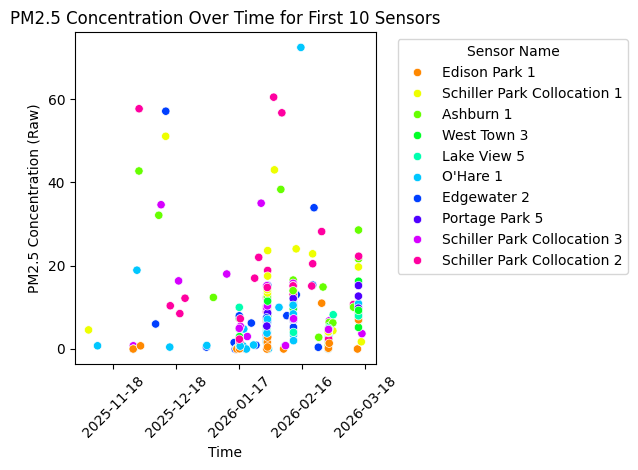

In [5]:
# Assign each unique sensor_name a distinct color using Seaborn's color_palette
unique_sensors = df['sensor_name'].unique()
print(f"Unique sensors found: {len(unique_sensors)}")
num_unique = 10
first_n_sensors = unique_sensors[:num_unique]
print(f"First {num_unique} unique sensors: {first_n_sensors}")
df_short = df[df['sensor_name'].isin(first_n_sensors)]
palette = sns.color_palette('hsv', n_colors=num_unique)
sensor_color_map = dict(zip(first_n_sensors, palette))
df_short['sensor_color'] = df_short['sensor_name'].map(sensor_color_map)
df_short.head(3)
df_short['time'] = pd.to_datetime(df_short['time'])
df_short['pm2_5concmassindividual_raw'] = df_short['pm2_5concmassindividual_raw'].astype(float)

sns.scatterplot(data = df_short, x = "time", y = "pm2_5concmassindividual_raw", hue = "sensor_name", palette = sensor_color_map)
plt.title("PM2.5 Concentration Over Time for First 10 Sensors")
plt.xlabel("Time")
plt.xticks(rotation=45)
plt.gca().xaxis.set_major_locator(plt.MaxNLocator(5))
plt.gca().yaxis.set_major_locator(plt.MaxNLocator(5))
plt.ylabel("PM2.5 Concentration (Raw)")
plt.legend(title="Sensor Name", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
# adjust this so I can select one sensor and see a time series of the pm2.5concmassindividual_raw values for that sensor over time, with the x-axis showing time and the y-axis showing the pm2.5concmassindividual_raw values.
# I will need a widget that allows me to select a sensor from the unique sensors in the dataset, and then the plot will update to show the time series for that selected sensor.
import ipywidgets as widgets
from ipywidgets import interact

# Allow for a filter for how many unique observations were made by each sensor, so I can select only sensors that have a certain number of observations or more. This will help me focus on sensors that have more data points and potentially more reliable readings.
sensor_counts = df['sensor_name'].value_counts()
print("Sensor observation counts:")
print(sensor_counts)
sensor_counts_widget = widgets.IntSlider(
    value=0,
    min=0,
    max=sensor_counts.max(),
    step=1,
    description='Min Observations:',
    continuous_update=False
)
# Create a dropdown widget for sensor selection
sensor_dropdown = widgets.Dropdown(
    options=unique_sensors,
    description='Select Sensor:',
    value=unique_sensors[0]  # Set default value to the first sensor
)

# Define a function to update the plot based on the selected sensor
def update_plot(selected_sensor, min_observations):
    # Filter the DataFrame based on the minimum observation count
    filtered_sensors = sensor_counts[sensor_counts >= min_observations].index

    
    # Filter the DataFrame for the selected sensor
    sensor_data = df[df['sensor_name'] == selected_sensor]
    sensor_data['time'] = pd.to_datetime(sensor_data['time'])
    sensor_data['pm2_5concmassindividual_raw'] = sensor_data['pm2_5concmassindividual_raw'].astype(float)
    
    # Create the time series plot
    plt.figure(figsize=(10, 6))
    sns.lineplot(data=sensor_data, x='time', y='pm2_5concmassindividual_raw')
    plt.title(f"PM2.5 Concentration Over Time for Sensor: {selected_sensor}")
    plt.xlabel("Time")
    plt.xticks(rotation=45)
    plt.gca().xaxis.set_major_locator(plt.MaxNLocator(10))
    plt.gca().yaxis.set_major_locator(plt.MaxNLocator(5))
    plt.ylabel("PM2.5 Concentration (Raw)")
    plt.tight_layout()
    plt.show()

# Use the interact function to create an interactive widget
interact(update_plot, selected_sensor=sensor_dropdown, min_observations=sensor_counts_widget)

Sensor observation counts:
sensor_name
Near North Side 4    76
Uptown 2             65
South Deering 7      60
O'Hare 1             38
Edgewater 2          30
                     ..
Near North Side 2     6
West Town 2           6
West Town 4           3
Loop 1                1
Near North Side 3     1
Name: count, Length: 282, dtype: int64


interactive(children=(Dropdown(description='Select Sensor:', options=('Edison Park 1', 'Schiller Park Collocat…

<function __main__.update_plot(selected_sensor, min_observations)>

In [9]:
# the above logic is lacking because I need to filter the sensors based on the minimum observation count before allowing the user to select a sensor. If a sensor does not meet the minimum observation count, it should not be available in the dropdown menu for selection. I need to update the dropdown options dynamically based on the selected minimum observation count, so that only sensors that have at least that many observations are shown in the dropdown. This way, I can ensure that users are only selecting from sensors that have sufficient data for analysis.

import ipywidgets as widgets
from ipywidgets import interact

sensor_counts = df['sensor_name'].value_counts()

sensor_counts_widget = widgets.IntSlider(
    value=0,
    min=0,
    max=sensor_counts.max(),
    step=1,
    description='Min Observations:',
    continuous_update=False
)
# Create a dropdown widget for sensor selection
sensor_dropdown = widgets.Dropdown(
    options=unique_sensors,
    description='Select Sensor:',
    value=unique_sensors[0]  # Set default value to the first sensor
)
def update_dropdown_options(min_observations):
    filtered_sensors = sensor_counts[sensor_counts >= min_observations].index
    sensor_dropdown.options = filtered_sensors
    if sensor_dropdown.value not in filtered_sensors:
        sensor_dropdown.value = None  # Reset selection if current value is not valid
sensor_counts_widget.observe(lambda change: update_dropdown_options(change['new']), names='value')
update_dropdown_options(sensor_counts_widget.value)  # Initialize dropdown options based on initial slider value

# Lets include a map that shows the locations of the sensors, and when you click on a sensor, it will show the time series plot for that sensor. This way, you can visually explore the spatial distribution of the sensors and their data.
def update_map(min_observations):
    filtered_sensors = sensor_counts[sensor_counts >= min_observations].index
    sensor_locations = df[df['sensor_name'].isin(filtered_sensors)][['sensor_name', 'latitude', 'longitude']].drop_duplicates()
    
    m = folium.Map(location=[41.8781, -87.6298], zoom_start=10)
    
    for _, row in sensor_locations.iterrows():
        folium.Marker(
            location=[row['latitude'], row['longitude']],
            popup=row['sensor_name']
        ).add_to(m)
    
    display(m)

def update_plot(selected_sensor, min_observations):
    if selected_sensor is None:
        print("Please select a sensor that meets the minimum observation count.")
        return
    
    # Filter the DataFrame for the selected sensor
    sensor_data = df[df['sensor_name'] == selected_sensor]
    sensor_data['time'] = pd.to_datetime(sensor_data['time'])
    sensor_data['pm2_5concmassindividual_raw'] = sensor_data['pm2_5concmassindividual_raw'].astype(float)
    
    # Create the time series plot
    plt.figure(figsize=(10, 6))
    sns.lineplot(data=sensor_data, x='time', y='pm2_5concmassindividual_raw')
    plt.title(f"PM2.5 Concentration Over Time for Sensor: {selected_sensor}")
    plt.xlabel("Time")
    plt.xticks(rotation=45)
    plt.gca().xaxis.set_major_locator(plt.MaxNLocator(10))
    plt.gca().yaxis.set_major_locator(plt.MaxNLocator(5))
    plt.ylabel("PM2.5 Concentration (Raw)")
    plt.tight_layout()
    plt.show()


interact(update_map, min_observations=sensor_counts_widget)

interact(update_plot, selected_sensor=sensor_dropdown, min_observations=sensor_counts_widget)

interactive(children=(IntSlider(value=0, continuous_update=False, description='Min Observations:', max=76), Ou…

interactive(children=(Dropdown(description='Select Sensor:', options=('Near North Side 4', 'Uptown 2', 'South …

<function __main__.update_plot(selected_sensor, min_observations)>

In [14]:
# at each timestep, plot all the sensors' PM2.5 values on a map with a color scale representing the average value of PM2.5, and the size of the marker representing the number of measurements taken by that sensor on a day.
plot_df = df.copy()
plot_df['time'] = pd.to_datetime(plot_df['time'])
plot_df['date'] = plot_df['time'].dt.date
plot_df['pm2_5concmassindividual_raw'] = plot_df['pm2_5concmassindividual_raw'].astype(float)
agg_df = plot_df.groupby(['sensor_name', 'date']).agg({
    'pm2_5concmassindividual_raw': 'mean',
    'time': 'count',
    'latitude': 'first',
    'longitude': 'first'
}).reset_index()
agg_df.rename(columns={'time': 'measurement_count'}, inplace=True)
agg_df.head(3)
display(agg_df.head())
# Create a folium map centered around Chicago
m = folium.Map(location=[41.8781, -87.6298], zoom_start=10, tiles = 'openstreetmap')
folium.TileLayer('CartoDB positron').add_to(m)
folium.TileLayer('CartoDB dark_matter').add_to(m)
# Add a marker cluster to the map
marker_cluster = plugins.MarkerCluster().add_to(m)
# Add markers to the cluster
for idx, row in agg_df.iterrows():
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=5 + row['measurement_count'] * 0.1,  # Size based on measurement count
        color='blue',
        fill=True,
        fill_color='blue',
        fill_opacity=0.6,
        popup=f"Sensor: {row['sensor_name']}<br>Date: {row['date']}<br>Avg PM2.5: {row['pm2_5concmassindividual_raw']:.2f}<br>Measurements: {row['measurement_count']}"
    ).add_to(marker_cluster)
        # Add layer control
folium.LayerControl().add_to(m) 
    # Add fullscreen button
plugins.Fullscreen().add_to(m)
# Display the map
display(m)
save_path = "../HTML_MAPS/chicago_aqi_mapped.html"
m.save(save_path)
print(f"Map saved to {save_path}")

,sensor_name,date,pm2_5concmassindividual_raw,measurement_count,latitude,longitude
0,Albany Park 1,2026-01-29,3.850000,1,41.9752872,-87.72557704250946
1,Albany Park 1,2026-01-30,7.486667,6,41.9752872,-87.72557704250946
2,Albany Park 1,2026-02-11,6.510000,3,41.9752872,-87.72557704250946
3,Albany Park 1,2026-02-28,1.695000,2,41.9752872,-87.72557704250946
4,Albany Park 1,2026-03-14,6.580000,1,41.9752872,-87.72557704250946


Map saved to ../HTML_MAPS/chicago_aqi_mapped.html


In [15]:
# Check for location/coordinate columns
print("Checking for location columns:")
location_cols = [col for col in df.columns if any(keyword in col.lower() 
                  for keyword in ['location', 'lat', 'lon', 'latitude', 'longitude', 'point', 'coordinates'])]
print(f"Location-related columns: {location_cols}")

# Display sample of location data
if location_cols:
    print("\nSample location data:")
    print(df[location_cols].head())

Checking for location columns:
Location-related columns: ['latitude', 'longitude', 'location']

Sample location data:
      latitude           longitude  \
0    42.017003          -87.816509   
1    41.965175          -87.876252   
2   41.7522794        -87.73751065   
3  41.89463405  -87.65461125155946   
4  41.93525075         -87.6725314   

                                            location  
0  {'type': 'Point', 'coordinates': [-87.816509, ...  
1  {'type': 'Point', 'coordinates': [-87.876252, ...  
2  {'type': 'Point', 'coordinates': [-87.73751065...  
3  {'type': 'Point', 'coordinates': [-87.65461125...  
4  {'type': 'Point', 'coordinates': [-87.6725314,...  


In [16]:
# Process location data
# Socrata APIs often store location as a dictionary in 'location' column
# We need to extract latitude and longitude

def extract_coordinates(row):
    """Extract latitude and longitude from location data"""
    if pd.isna(row):
        return None, None
    
    # If location is a string, try to parse it as JSON
    if isinstance(row, str):
        try:
            loc_data = json.loads(row)
            if 'latitude' in loc_data and 'longitude' in loc_data:
                return loc_data['latitude'], loc_data['longitude']
            elif 'coordinates' in loc_data:
                # GeoJSON format: [longitude, latitude]
                coords = loc_data['coordinates']
                return coords[1], coords[0]
        except:
            pass
    
    # If location is already a dict
    if isinstance(row, dict):
        if 'latitude' in row and 'longitude' in row:
            return row['latitude'], row['longitude']
        elif 'coordinates' in row:
            coords = row['coordinates']
            return coords[1], coords[0]
    
    return None, None

# Try to extract coordinates
if 'location' in df.columns:
    coords = df['location'].apply(extract_coordinates)
    df['latitude'] = coords.apply(lambda x: x[0] if x[0] is not None else None)
    df['longitude'] = coords.apply(lambda x: x[1] if x[1] is not None else None)
    
    # Remove rows without valid coordinates
    df_geo = df.dropna(subset=['latitude', 'longitude']).copy()
    df_geo['latitude'] = df_geo['latitude'].astype(float)
    df_geo['longitude'] = df_geo['longitude'].astype(float)
    
    print(f"Records with valid coordinates: {len(df_geo)}")
    print(f"Records without coordinates: {len(df) - len(df_geo)}")
else:
    print("No 'location' column found. Checking for other coordinate columns...")
    # Check if lat/lon columns exist directly
    if 'latitude' in df.columns and 'longitude' in df.columns:
        df_geo = df.dropna(subset=['latitude', 'longitude']).copy()
        df_geo['latitude'] = pd.to_numeric(df_geo['latitude'], errors='coerce')
        df_geo['longitude'] = pd.to_numeric(df_geo['longitude'], errors='coerce')
        df_geo = df_geo.dropna(subset=['latitude', 'longitude'])
        print(f"Records with valid coordinates: {len(df_geo)}")
    else:
        print("Could not find location data. Please check the dataset structure.")
        df_geo = df.copy()

Records with valid coordinates: 5000
Records without coordinates: 0


In [17]:
# Create interactive map centered on Chicago
# Calculate center point
if len(df_geo) > 0:
    center_lat = df_geo['latitude'].mean()
    center_lon = df_geo['longitude'].mean()
    
    # Create base map
    chicago_map = folium.Map(
        location=[center_lat, center_lon],
        zoom_start=11,
        tiles='OpenStreetMap'
    )
    
    # Add different tile layers
    folium.TileLayer('CartoDB positron').add_to(chicago_map)
    folium.TileLayer('CartoDB dark_matter').add_to(chicago_map)
    
    print(f"Map created centered at: ({center_lat:.4f}, {center_lon:.4f})")
    print(f"Total sensors to plot: {len(df_geo)}")
else:
    print("No geographic data available to create map")

Map created centered at: (41.8345, -87.6803)
Total sensors to plot: 5000


In [18]:
# Add sensors to map with popup information
if len(df_geo) > 0:
    # Identify sensor ID column (common names)
    sensor_id_col = None
    for col in ['sensor_id', 'sensor', 'id', 'sensor_name', 'name', 'site_id']:
        if col in df_geo.columns:
            sensor_id_col = col
            break
    
    # Identify AQI/value columns
    aqi_cols = [col for col in df_geo.columns if any(keyword in col.lower() 
                for keyword in ['aqi', 'value', 'reading', 'measurement', 'pm', 'no2', 'o3'])]
    
    # Create feature group for sensors
    sensor_group = folium.FeatureGroup(name='Air Quality Sensors')
    
    # Add markers for each sensor
    for idx, row in df_geo.iterrows():
        # Get sensor identifier
        sensor_id = row[sensor_id_col] if sensor_id_col else f"Sensor {idx}"
        
        # Create popup content with available information
        popup_content = f"<div style='width: 250px;'>"
        popup_content += f"<h4>{sensor_id}</h4>"
        popup_content += f"<b>Location:</b> ({row['latitude']:.4f}, {row['longitude']:.4f})<br>"
        
        # Add AQI/measurement values if available
        if aqi_cols:
            popup_content += "<hr><b>Measurements:</b><br>"
            for col in aqi_cols[:5]:  # Show first 5 measurement columns
                if pd.notna(row[col]):
                    popup_content += f"<b>{col}:</b> {row[col]}<br>"
        
        # Add timestamp if available
        time_cols = [col for col in df_geo.columns if any(keyword in col.lower() 
                    for keyword in ['time', 'date', 'timestamp', 'created'])]
        if time_cols:
            popup_content += f"<hr><b>{time_cols[0]}:</b> {row[time_cols[0]]}<br>"
        
        popup_content += "</div>"
        
        # Create marker
        folium.CircleMarker(
            location=[row['latitude'], row['longitude']],
            radius=8,
            popup=folium.Popup(popup_content, max_width=300),
            tooltip=f"{sensor_id}",
            color='blue',
            fillColor='lightblue',
            fillOpacity=0.7,
            weight=2
        ).add_to(sensor_group)
    
    sensor_group.add_to(chicago_map)
    
    # Add layer control
    folium.LayerControl().add_to(chicago_map)
    
    # Add fullscreen button
    plugins.Fullscreen().add_to(chicago_map)
    
    # Display map
    chicago_map
else:
    print("No geographic data available to plot sensors")

In [20]:
# Save map to HTML file
if len(df_geo) > 0:
    chicago_map.save('../HTML_MAPS/chicago_aqi_sensors_map.html')
    print("Map saved as '../HTML_MAPS/chicago_aqi_sensors_map.html'")
    print("You can open this file in a web browser to interact with the map.")

Map saved as '../HTML_MAPS/chicago_aqi_sensors_map.html'
You can open this file in a web browser to interact with the map.


---

## Data Preprocessing for Time Series Analysis

**User Request:** 
> "lets continue with data preprocessing! Lets prepare for time series analysis. I would like a visualization where we create an interpolated map using IDW, Krigging, and eventually other methods to display the change in time series. I would like it to have a time bar that you can press play and watch it evovle. I would also like it to display a stats bar with average, max, min, std and quantiles(both good quality and bad) so that you can select the quantile and see the regions where the air quality falls in one of the regions.

> Eventually we are going to compare this with census data to see where the data is collected, how the aire quality (and generally data quality) compares with the social economic qualities of census groups/blocks.

> I would like this to be designed so that I can send it to someone and they can read and interact with the visualizations in the notebook, or we can make a document using Quatro or MyST. Also I want to provide transparency with my workflow so include my prompts in markdown cells at the points when I ask to add information."

**Goals:**
- Prepare data for time series analysis
- Implement IDW (Inverse Distance Weighting) interpolation
- Implement Kriging interpolation
- Create animated time-series visualization with play controls
- Add statistics panel (avg, max, min, std, quantiles)
- Enable quantile-based region highlighting

In [21]:
# Import additional libraries for interpolation and interactive visualization
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
from scipy.spatial.distance import cdist
from scipy.interpolate import griddata
from pykrige import OrdinaryKriging
from sklearn.preprocessing import StandardScaler
import ipywidgets as widgets
from IPython.display import display, HTML
from datetime import timedelta

print("Additional libraries imported successfully!")

Additional libraries imported successfully!


In [22]:
# Time Series Data Preprocessing
# Convert time column to datetime
df_geo['time'] = pd.to_datetime(df_geo['time'])

# Select primary air quality metric (PM2.5)
aqi_column = 'pm2_5concmassindividual_value'

# Clean and prepare data for time series analysis
df_ts = df_geo.copy()

# Remove rows with missing coordinates or AQI values
df_ts = df_ts.dropna(subset=['latitude', 'longitude', aqi_column])

# Convert AQI to numeric
df_ts[aqi_column] = pd.to_numeric(df_ts[aqi_column], errors='coerce')
df_ts = df_ts.dropna(subset=[aqi_column])

# Sort by time
df_ts = df_ts.sort_values('time').reset_index(drop=True)

# Get time range
time_min = df_ts['time'].min()
time_max = df_ts['time'].max()

print(f"Time Series Data Prepared:")
print(f"  Total records: {len(df_ts)}")
print(f"  Time range: {time_min} to {time_max}")
print(f"  Unique sensors: {df_ts['sensor_name'].nunique()}")
print(f"  Unique timestamps: {df_ts['time'].nunique()}")
print(f"\nAQI Statistics:")
print(f"  Mean: {df_ts[aqi_column].mean():.2f}")
print(f"  Std: {df_ts[aqi_column].std():.2f}")
print(f"  Min: {df_ts[aqi_column].min():.2f}")
print(f"  Max: {df_ts[aqi_column].max():.2f}")
print(f"  25th percentile: {df_ts[aqi_column].quantile(0.25):.2f}")
print(f"  50th percentile: {df_ts[aqi_column].quantile(0.50):.2f}")
print(f"  75th percentile: {df_ts[aqi_column].quantile(0.75):.2f}")
print(f"  95th percentile: {df_ts[aqi_column].quantile(0.95):.2f}")

Time Series Data Prepared:
  Total records: 4978
  Time range: 2025-11-06 03:22:24.413000 to 2026-03-19 23:48:02
  Unique sensors: 282
  Unique timestamps: 4892

AQI Statistics:
  Mean: 7.55
  Std: 3.49
  Min: 1.75
  Max: 61.06
  25th percentile: 5.37
  50th percentile: 6.80
  75th percentile: 9.00
  95th percentile: 12.48


In [23]:
# Create time bins for aggregation (e.g., hourly or daily)
# This helps reduce noise and create smoother animations
time_bin_size = '12h'  # Can be changed to '30min', '1H', '6H', '1D', etc.

df_ts['time_bin'] = df_ts['time'].dt.floor(time_bin_size)

# Aggregate data by sensor and time bin (take mean of multiple readings)
df_aggregated = df_ts.groupby(['sensor_name', 'time_bin', 'latitude', 'longitude'])[aqi_column].mean().reset_index()
df_aggregated = df_aggregated.rename(columns={aqi_column: 'aqi_value', 'time_bin': 'time'})

# Get unique timestamps for animation
unique_times = sorted(df_aggregated['time'].unique())

print(f"Aggregation complete:")
print(f"  Time bin size: {time_bin_size}")
print(f"  Unique time bins: {len(unique_times)}")
print(f"  Records per time bin (avg): {len(df_aggregated) / len(unique_times):.1f}")

# Display sample of aggregated data
print(f"\nSample aggregated data:")
df_aggregated.head()

Aggregation complete:
  Time bin size: 12h
  Unique time bins: 71
  Records per time bin (avg): 29.8

Sample aggregated data:


,sensor_name,time,latitude,longitude,aqi_value
0,Albany Park 1,2026-01-29 12:00:00,41.975287,-87.725577,9.5500
1,Albany Park 1,2026-01-30 00:00:00,41.975287,-87.725577,7.5775
2,Albany Park 1,2026-01-30 12:00:00,41.975287,-87.725577,8.7650
3,Albany Park 1,2026-02-11 12:00:00,41.975287,-87.725577,7.6700
4,Albany Park 1,2026-02-28 12:00:00,41.975287,-87.725577,5.9850


## NEXT STEPS:

I am intersted in the quality of the data so I would like to create a map of the data that is a time dimension. The idea would be to bin the observations into different time bins, instantaneous, hour, 6 hour, 12 hr, day, week. The visualization would be a map that has red dots for stations not recording and green dots for stations that are in that interval of time. The importance is to see at what agglomerative period can we extract enough info to run analysis. I would like to create time dependent models but those that deal with 1 tracker per time step would not be so valuable. In the corner of the map we should have a stats tab which is saying the number observing and the number not umbserving, the agglomerative period, the mean value, the std, the spatial range(max distance between sensors), mean spatial distance, min spatial distance.

"Can you create a simple map that agglomerates data based on selected interval and maps the stations in red/green and shows these stats?"

In [24]:
print(aqi_column)

pm2_5concmassindividual_value


In [25]:
# Time-binned uptime map with stats (red = not observing, green = observing)
import numpy as np
import pandas as pd
import plotly.express as px
import ipywidgets as widgets

# Catalog of all sensors with their latest coordinates and total observation counts
sensor_catalog = (
    df_ts.sort_values('time')
    .groupby('sensor_name')
    .agg(
        latitude=('latitude', 'last'),
        longitude=('longitude', 'last'),
        total_obs=('pm2_5concmassindividual_value', 'size')
    )
    .reset_index()
)

# Available bin sizes (Pandas offset aliases)
bin_labels = {
    '1 hour': '1h',
    '6 hours': '6h',
    '12 hours': '12h',
    '1 day': '1D',
    '2 day': '2D',
    '3 day': '3D',
    '4 day': '4D',
    '5 day': '5D',
    '1 week': '7D'
}

COVERAGE_OPTIONS = {
    "0%+ sensors": 0.0,
    "25%+ sensors": 0.25,
    "50%+ sensors": 0.5,
    "60%+ sensors": 0.6,
    "75%+ sensors": 0.75
}

aggregate_cache = {}



def aggregate_for_bin(bin_code: str) -> pd.DataFrame:
    """Aggregate df_ts into the requested time bin and cache the result."""
    if bin_code in aggregate_cache:
        return aggregate_cache[bin_code]

    df_tmp = df_ts.copy()
    df_tmp['time_bin'] = df_tmp['time'].dt.floor(bin_code)
    agg = (
        df_tmp.groupby(['sensor_name', 'time_bin', 'latitude', 'longitude'])['pm2_5concmassindividual_value']
        .agg(pm2_5concmassindividual_value='mean', reading_count='size')
        .reset_index()
        .rename(columns={'time_bin': 'time'})
        .sort_values('time')
    )
    aggregate_cache[bin_code] = agg
    return agg


def haversine_matrix(df_points: pd.DataFrame) -> np.ndarray:
    """Return upper-triangle pairwise distances (km) for the given lat/lon points."""
    if len(df_points) < 2:
        return np.array([])
    coords_rad = np.radians(df_points[['latitude', 'longitude']].to_numpy())
    lat = coords_rad[:, 0][:, None]
    lon = coords_rad[:, 1][:, None]
    dlat = lat - lat.T
    dlon = lon - lon.T
    a = np.sin(dlat / 2) ** 2 + np.cos(lat) * np.cos(lat.T) * (np.sin(dlon / 2) ** 2)
    dist_matrix = 2 * 6371.0 * np.arcsin(np.sqrt(a))  # Earth radius ~6371 km
    return dist_matrix[np.triu_indices(len(df_points), k=1)]


def distance_stats(df_points: pd.DataFrame) -> dict:
    dists = haversine_matrix(df_points)
    if dists.size == 0:
        return {'range_km': 0.0, 'mean_km': 0.0, 'min_km': 0.0}
    return {
        'range_km': float(dists.max()),
        'mean_km': float(dists.mean()),
        'min_km': float(dists.min()),
    }


def filtered_time_options(agg: pd.DataFrame, min_share: float) -> list[pd.Timestamp]:
    if agg.empty:
        return []
    total_sensors = len(sensor_catalog) or 1
    coverage = agg.groupby('time')['sensor_name'].nunique() / total_sensors
    valid = coverage[coverage >= min_share]
    if valid.empty:
        return []
    return list(valid.index.sort_values())


# Widgets
bin_dropdown = widgets.Dropdown(
    options=list(bin_labels.keys()),
    value='12 hours',
    description='Bin:',
    layout=widgets.Layout(width='200px')
)

time_slider = widgets.SelectionSlider(
    options=[df_ts['time'].min(), df_ts['time'].max()],
    description='Time:',
    layout=widgets.Layout(width='500px'),
    continuous_update=False
)
min_observing_share_dropdown = widgets.Dropdown(
    options=list(COVERAGE_OPTIONS.keys()),
    value="0%+ sensors",
    description="Min coverage:",
    layout=widgets.Layout(width='220px')
)

map_out = widgets.Output()


def update_time_options(bin_label: str, coverage_label: str):
    bin_code = bin_labels[bin_label]
    min_share = COVERAGE_OPTIONS[coverage_label]
    agg = aggregate_for_bin(bin_code)
    options = filtered_time_options(agg, min_share)
    if not options:
        time_slider.options = []
        time_slider.value = None
        return
    time_slider.options = options
    time_slider.value = options[0]
    return options


def render_map(_=None):
    bin_label = bin_dropdown.value
    coverage_label = min_observing_share_dropdown.value
    bin_code = bin_labels[bin_label]
    agg = aggregate_for_bin(bin_code)
    current_time = pd.to_datetime(time_slider.value) if time_slider.value is not None else None
    if current_time is None:
        with map_out:
            map_out.clear_output(wait=True)
            print('No data available for the selected bin / coverage threshold.')
        return

    df_time = agg[agg['time'] == current_time].copy()
    active_ids = set(df_time['sensor_name'])

    # Build status table for plotting
    status_df = sensor_catalog.copy()
    status_df['status'] = np.where(status_df['sensor_name'].isin(active_ids), 'Observing', 'Not observing')
    status_df = status_df.merge(
        df_time[['sensor_name', 'pm2_5concmassindividual_value', 'reading_count']],
        on='sensor_name',
        how='left'
    )
    status_df['bin_readings'] = status_df.pop('reading_count').fillna(0).astype(int)

    # Stats
    observing = len(active_ids)
    total = len(status_df)
    not_observing = total - observing
    coverage_pct = (observing / total * 100) if total else 0.0
    value_mean = df_time['pm2_5concmassindividual_value'].mean() if observing else np.nan
    value_std = df_time['pm2_5concmassindividual_value'].std() if observing else np.nan
    dist_stats = distance_stats(df_time)

    stats_text = '<br>'.join([
        f'Bin: {bin_label} ({bin_code})',
        f'Time: {current_time}',
        f'Observing: {observing} / {total}',
        f'Not observing: {not_observing}',
        f'Coverage: {coverage_pct:.1f}%',
        f'Mean value: {value_mean:.2f}' if not np.isnan(value_mean) else 'Mean value: N/A',
        f'Std: {value_std:.2f}' if not np.isnan(value_std) else 'Std: N/A',
        f'Spatial range (km): {dist_stats["range_km"]:.1f}',
        f'Mean dist (km): {dist_stats["mean_km"]:.1f}',
        f'Min dist (km): {dist_stats["min_km"]:.1f}'
    ])

    fig = px.scatter_mapbox(
        status_df,
        lat='latitude',
        lon='longitude',
        color='status',
        color_discrete_map={'Observing': 'green', 'Not observing': 'red'},
        hover_name='sensor_name',
        hover_data={
            'pm2_5concmassindividual_value': ':.2f',
            'bin_readings': ':.0f',
            'total_obs': ':.0f',
            'status': False,
            'latitude': ':.4f',
            'longitude': ':.4f'
        },
        zoom=9,
        height=600,
        size_max=14,
    )
    fig.update_traces(marker=dict(size=np.where(status_df['status'] == 'Observing', 14, 9)))
    fig.update_layout(
        mapbox_style='carto-positron',
        margin=dict(l=10, r=10, t=40, b=10),
        title=f'Sensor uptime by {bin_label} bin',
        legend=dict(orientation='h', yanchor='bottom', y=0.01, xanchor='left', x=0.01)
    )
    fig.add_annotation(
        x=0.99, y=0.99, xref='paper', yref='paper', showarrow=False,
        align='left', bgcolor='rgba(255,255,255,0.85)', bordercolor='gray',
        borderwidth=1, borderpad=6, text=stats_text, font=dict(size=12)
    )

    with map_out:
        map_out.clear_output(wait=True)        
        display(fig)
    


def on_bin_change(change):
    if change['name'] == 'value':
        update_time_options(change['new'], min_observing_share_dropdown.value)
        render_map()


def on_time_change(change):
    if change['name'] == 'value' and change['new'] is not None:
        render_map()


def on_observing_share_change(change):
    if change['name'] == 'value':
        update_time_options(bin_dropdown.value, change['new'])
        render_map()


# Wire up callbacks and render initial view
bin_dropdown.observe(on_bin_change, names='value')
time_slider.observe(on_time_change, names='value')
min_observing_share_dropdown.observe(on_observing_share_change, names='value')
update_time_options(bin_dropdown.value, min_observing_share_dropdown.value)
render_map()

controls = widgets.HBox([bin_dropdown, time_slider, min_observing_share_dropdown])
print("Times which meet the minimum observing share threshold are available in the time slider. Adjust the bin size and coverage threshold to see how it affects sensor uptime.")
display(controls, map_out)



Times which meet the minimum observing share threshold are available in the time slider. Adjust the bin size and coverage threshold to see how it affects sensor uptime.


Output()

In [26]:
aggregate_for_bin('5D').head()

,sensor_name,time,latitude,longitude,pm2_5concmassindividual_value,reading_count
1128,Schiller Park Collocation 1,2025-11-03,41.965175,-87.876252,6.33,1
992,O'Hare 1,2025-11-08,41.976284,-87.852764,3.26,1
1151,Schiller Park Collocation 3,2025-11-23,41.965175,-87.876252,4.02,1
993,O'Hare 1,2025-11-23,41.976284,-87.852764,3.77,1
404,Edison Park 1,2025-11-23,42.017003,-87.816509,3.56,1


Interpolation functions defined!
           sensor_name        time   latitude  longitude  \
252    Brighton Park 2  2026-01-17  41.815089 -87.686175   
567        Hegewisch 4  2026-01-17  41.649651 -87.552766   
561        Hegewisch 3  2026-01-17  41.650308 -87.536575   
267  Calumet Heights 1  2026-01-17  41.726125 -87.586237   
970     Norwood Park 3  2026-01-17  41.989852 -87.780296   

     pm2_5concmassindividual_value  reading_count  
252                          4.485              2  
567                          5.080              4  
561                          4.030              1  
267                          4.740              2  
970                          4.485              2  

Creating interpolation grid visualization for: 2026-01-17 00:00:00
Number of sensors: 251


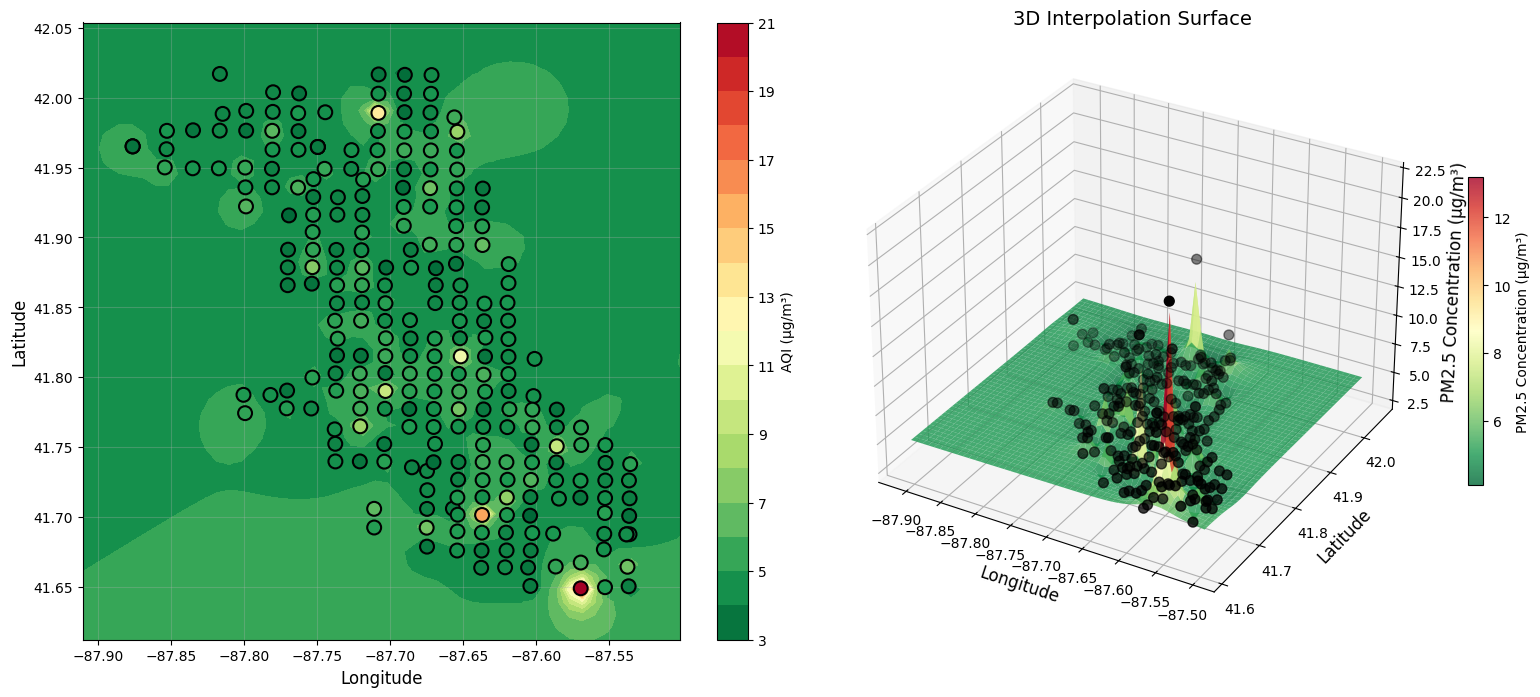


Grid Information:
  Grid resolution: 50 x 50
  Longitude range: -87.9103 to -87.5014
  Latitude range: 41.6121 to 42.0538
  Interpolated PM2.5 range: 3.64 to 20.73
  Mean interpolated PM2.5: 4.99


In [27]:
# Interpolation Functions

def aggregate_for_bin(bin_code: str) -> pd.DataFrame:
    """Aggregate df_ts into the requested time bin and cache the result."""
    if bin_code in aggregate_cache:
        return aggregate_cache[bin_code]

    df_tmp = df_ts.copy()
    df_tmp['time_bin'] = df_tmp['time'].dt.floor(bin_code)
    agg = (
        df_tmp.groupby(['sensor_name', 'time_bin', 'latitude', 'longitude'])['pm2_5concmassindividual_value']
        .agg(pm2_5concmassindividual_value='mean', reading_count='size')
        .reset_index()
        .rename(columns={'time_bin': 'time'})
        .sort_values('time')
    )
    aggregate_cache[bin_code] = agg
    return agg


def idw_interpolation(points, values, grid_x, grid_y, power=2, max_distance=None):
    """
    Inverse Distance Weighting (IDW) interpolation
    
    Parameters:
    - points: array of (x, y) coordinates of known points
    - values: array of values at known points
    - grid_x, grid_y: meshgrid of interpolation points
    - power: power parameter (higher = more influence from nearby points)
    - max_distance: maximum distance to consider (None = use all points)
    """
    # Flatten grid
    grid_points = np.column_stack([grid_x.ravel(), grid_y.ravel()])
    
    # Calculate distances from each grid point to each known point
    distances = cdist(grid_points, points)
    
    # Avoid division by zero
    distances[distances == 0] = 1e-10
    
    # Apply max_distance if specified
    if max_distance is not None:
        distances[distances > max_distance] = np.inf
    
    # Calculate weights (inverse distance raised to power)
    weights = 1.0 / (distances ** power)
    
    # Handle points with no nearby neighbors
    weights[weights == np.inf] = 0
    
    # Normalize weights
    weight_sums = weights.sum(axis=1)
    weight_sums[weight_sums == 0] = 1  # Avoid division by zero
    weights = weights / weight_sums[:, np.newaxis]
    
    # Interpolate values
    interpolated = np.dot(weights, values)
    
    # Reshape to grid
    return interpolated.reshape(grid_x.shape)


def kriging_interpolation(points, values, grid_x, grid_y, variogram_model='linear'):
    """
    Ordinary Kriging interpolation
    
    Parameters:
    - points: array of (x, y) coordinates of known points
    - values: array of values at known points
    - grid_x, grid_y: meshgrid of interpolation points
    - variogram_model: variogram model ('linear', 'spherical', 'gaussian', 'exponential')
    """
    try:
        # Create OrdinaryKriging object
        ok = OrdinaryKriging(
            points[:, 0],  # x coordinates
            points[:, 1],  # y coordinates
            values,
            variogram_model=variogram_model,
            verbose=False,
            enable_plotting=False,
            nlags=6
        )
        
        # Interpolate on grid
        z, ss = ok.execute('grid', grid_x[0, :], grid_y[:, 0])
        
        return z
    except Exception as e:
        print(f"Kriging failed: {e}")
        # Fallback to IDW if Kriging fails
        return idw_interpolation(points, values, grid_x, grid_y)


def create_interpolation_grid(df_time_slice, method='idw', grid_resolution=100):
    """
    Create interpolated surface for a single time slice
    
    Parameters:
    - df_time_slice: DataFrame with columns ['latitude', 'longitude', 'pm2_5concmassindividual_value']
    - method: 'idw' or 'kriging'
    - grid_resolution: number of grid points in each direction
    """
    if len(df_time_slice) < 3:
        return None, None, None, None
    
    # Get bounding box
    lat_min, lat_max = df_time_slice['latitude'].min(), df_time_slice['latitude'].max()
    lon_min, lon_max = df_time_slice['longitude'].min(), df_time_slice['longitude'].max()
    
    # Add padding
    lat_padding = (lat_max - lat_min) * 0.1
    lon_padding = (lon_max - lon_min) * 0.1
    
    # Create grid
    lat_grid = np.linspace(lat_min - lat_padding, lat_max + lat_padding, grid_resolution)
    lon_grid = np.linspace(lon_min - lon_padding, lon_max + lon_padding, grid_resolution)
    grid_lon, grid_lat = np.meshgrid(lon_grid, lat_grid)
    
    # Prepare known points
    points = np.column_stack([df_time_slice['longitude'].values, 
                              df_time_slice['latitude'].values])
    values = df_time_slice['pm2_5concmassindividual_value'].values
    
    # Interpolate
    if method.lower() == 'idw':
        interpolated = idw_interpolation(points, values, grid_lon, grid_lat, power=2)
    elif method.lower() == 'kriging':
        interpolated = kriging_interpolation(points, values, grid_lon, grid_lat)
    else:
        raise ValueError(f"Unknown method: {method}")
    
    return grid_lon, grid_lat, interpolated, df_time_slice

print("Interpolation functions defined!")

# Test and visualize the interpolation grid
# Select a sample time slice for visualization
if len(time_slider.options) > 0:
    sample_time = time_slider.options[0]  # Use first time in the slider options
    sample_date = pd.to_datetime(sample_time).date()
    current_agg = aggregate_for_bin('5D')  # Use 5-day bin for more data points
    current_agg['time'] = pd.to_datetime(current_agg['time']).dt.date
    df_sample = current_agg[current_agg['time'] == sample_date].copy()
    print(df_sample.head())
    if len(df_sample) >= 3:
        print(f"\nCreating interpolation grid visualization for: {sample_time}")
        print(f"Number of sensors: {len(df_sample)}")
        
        # Create interpolation grid using IDW
        grid_lon, grid_lat, interpolated, _ = create_interpolation_grid(
            df_sample, method='idw', grid_resolution=50
        )
        
        if interpolated is not None:
            # Create visualization using matplotlib
            import matplotlib.pyplot as plt
            from mpl_toolkits.mplot3d import Axes3D
            
            fig = plt.figure(figsize=(16, 7))
            
            # Plot 1: Contour plot of interpolated surface
            ax1 = fig.add_subplot(121)
            contour = ax1.contourf(grid_lon, grid_lat, interpolated, levels=20, cmap='RdYlGn_r')
            ax1.scatter(df_sample['longitude'], df_sample['latitude'], 
                       c=df_sample['pm2_5concmassindividual_value'], s=100, cmap='RdYlGn_r',
                       edgecolors='black', linewidths=1.5, zorder=5)
            ax1.set_xlabel('Longitude', fontsize=12)
            ax1.set_ylabel('Latitude', fontsize=12)
            # ax1.set_title(f'IDW Interpolation Grid\nTime: {sample_time.strftime(\"%Y-%m-%d %H:%M\")}', fontsize=14)
            ax1.grid(True, alpha=0.3)
            plt.colorbar(contour, ax=ax1, label='AQI (μg/m³)')
            
            # Plot 2: 3D surface plot
            ax2 = fig.add_subplot(122, projection='3d')
            surf = ax2.plot_surface(grid_lon, grid_lat, interpolated, 
                                   cmap='RdYlGn_r', alpha=0.8, 
                                   linewidth=0, antialiased=True)
            ax2.scatter(df_sample['longitude'], df_sample['latitude'], 
                       df_sample['pm2_5concmassindividual_value'], c='black', s=50, zorder=5)
            ax2.set_xlabel('Longitude', fontsize=12)
            ax2.set_ylabel('Latitude', fontsize=12)
            ax2.set_zlabel('PM2.5 Concentration (μg/m³)', fontsize=12)
            ax2.set_title('3D Interpolation Surface', fontsize=14)
            plt.colorbar(surf, ax=ax2, label='PM2.5 Concentration (μg/m³)', shrink=0.5)
            
            plt.tight_layout()
            plt.show()
            
            # Print grid information
            print(f"\nGrid Information:")
            print(f"  Grid resolution: {interpolated.shape[0]} x {interpolated.shape[1]}")
            print(f"  Longitude range: {grid_lon.min():.4f} to {grid_lon.max():.4f}")
            print(f"  Latitude range: {grid_lat.min():.4f} to {grid_lat.max():.4f}")
            print(f"  Interpolated PM2.5 range: {interpolated.min():.2f} to {interpolated.max():.2f}")
            print(f"  Mean interpolated PM2.5: {interpolated.mean():.2f}")
        else:
            print("Failed to create interpolation grid")
    else:
        print(f"Not enough data points for time slice {sample_time}")
else:
    print("No time slices available for visualization")

In [ ]:
# make a widget that is the full pipline from above...

import numpy as np
import pandas as pd
import plotly.express as px
import ipywidgets as widgets

# Catalog of all sensors with their latest coordinates and total observation counts
sensor_catalog = (
    df_ts.sort_values('time')
    .groupby('sensor_name')
    .agg(
        latitude=('latitude', 'last'),
        longitude=('longitude', 'last'),
        total_obs=('pm2_5concmassindividual_value', 'size')
    )
    .reset_index()
 )

# Available bin sizes (Pandas offset aliases)
bin_labels = {
    '1 hour': '1h',
    '6 hours': '6h',
    '12 hours': '12h',
    '1 day': '1D',
    '2 day': '2D',
    '3 day': '3D',
    '4 day': '4D',
    '5 day': '5D',
    '1 week': '7D'
}

COVERAGE_OPTIONS = {
    '0%+ sensors': 0.0,
    '25%+ sensors': 0.25,
    '50%+ sensors': 0.5,
    '60%+ sensors': 0.6,
    '75%+ sensors': 0.75
}

aggregate_cache = {}

def aggregate_for_bin(bin_code: str) -> pd.DataFrame:
    '''Aggregate df_ts into the requested time bin and cache the result.'''
    if bin_code in aggregate_cache:
        return aggregate_cache[bin_code]

    df_tmp = df_ts.copy()
    df_tmp['time_bin'] = df_tmp['time'].dt.floor(bin_code)
    agg = (
        df_tmp.groupby(['sensor_name', 'time_bin', 'latitude', 'longitude'])['pm2_5concmassindividual_value']
        .agg(pm2_5concmassindividual_value='mean', reading_count='size')
        .reset_index()
        .rename(columns={'time_bin': 'time'})
        .sort_values('time')
    )
    aggregate_cache[bin_code] = agg
    return agg

def haversine_matrix(df_points: pd.DataFrame) -> np.ndarray:
    '''Return upper-triangle pairwise distances (km) for the given lat/lon points.'''
    if len(df_points) < 2:
        return np.array([])
    coords_rad = np.radians(df_points[['latitude', 'longitude']].to_numpy())
    lat = coords_rad[:, 0][:, None]
    lon = coords_rad[:, 1][:, None]
    dlat = lat - lat.T
    dlon = lon - lon.T
    a = np.sin(dlat / 2) ** 2 + np.cos(lat) * np.cos(lat.T) * (np.sin(dlon / 2) ** 2)
    dist_matrix = 2 * 6371.0 * np.arcsin(np.sqrt(a))
    return dist_matrix[np.triu_indices(len(df_points), k=1)]

def distance_stats(df_points: pd.DataFrame) -> dict:
    dists = haversine_matrix(df_points)
    if dists.size == 0:
        return {'range_km': 0.0, 'mean_km': 0.0, 'min_km': 0.0}
    return {
        'range_km': float(dists.max()),
        'mean_km': float(dists.mean()),
        'min_km': float(dists.min()),
    }

def filtered_time_options(agg: pd.DataFrame, min_share: float) -> list[pd.Timestamp]:
    if agg.empty:
        return []
    total_sensors = len(sensor_catalog) or 1
    coverage = agg.groupby('time')['sensor_name'].nunique() / total_sensors
    valid = coverage[coverage >= min_share]
    if valid.empty:
        return []
    return list(valid.index.sort_values())

# Widgets
bin_dropdown = widgets.Dropdown(
    options=list(bin_labels.keys()),
    value='12 hours',
    description='Bin:',
    layout=widgets.Layout(width='180px')
)

time_slider = widgets.SelectionSlider(
    options=[df_ts['time'].min()],
    value=df_ts['time'].min(),
    description='Time:',
    layout=widgets.Layout(width='420px'),
    continuous_update=False,
    disabled=True
)

min_observing_share_dropdown = widgets.Dropdown(
    options=list(COVERAGE_OPTIONS.keys()),
    value='0%+ sensors',
    description='Min coverage:',
    layout=widgets.Layout(width='200px')
)

idw_button = widgets.Button(
    description='Show IDW Interpolation',
    tooltip='Generate an IDW contour for the current time slice',
    layout=widgets.Layout(width='220px')
)

map_out = widgets.Output(
    layout=widgets.Layout(width='65%', min_height='640px', border='1px solid #ddd', padding='10px')
)
interpolation_out = widgets.Output(
    layout=widgets.Layout(width='35%', min_height='640px', border='1px solid #ddd', padding='10px')
)

def show_interpolation_message(message: str) -> None:
    with interpolation_out:
        interpolation_out.clear_output(wait=True)
        print(message)

def update_time_options(bin_label: str, coverage_label: str):
    bin_code = bin_labels[bin_label]
    min_share = COVERAGE_OPTIONS[coverage_label]
    agg = aggregate_for_bin(bin_code)
    options = filtered_time_options(agg, min_share)
    if not options:
        time_slider.options = []
        time_slider.value = None
        time_slider.disabled = True
        with map_out:
            map_out.clear_output(wait=True)
            print('No data available for the selected bin / coverage threshold.')
        show_interpolation_message('Select a bin and coverage combo that yields at least one valid time slice.')
        return []
    time_slider.options = options
    time_slider.value = options[0]
    time_slider.disabled = False
    return options

def render_map(_=None):
    bin_label = bin_dropdown.value
    coverage_label = min_observing_share_dropdown.value
    bin_code = bin_labels[bin_label]
    agg = aggregate_for_bin(bin_code)
    current_time = pd.to_datetime(time_slider.value) if time_slider.value is not None else None
    if current_time is None:
        with map_out:
            map_out.clear_output(wait=True)
            print('No data available for the selected bin / coverage threshold.')
        show_interpolation_message('Select a time with sufficient coverage to enable interpolation.')
        return

    df_time = agg[agg['time'] == current_time].copy()
    active_ids = set(df_time['sensor_name'])

    status_df = sensor_catalog.copy()
    status_df['status'] = np.where(status_df['sensor_name'].isin(active_ids), 'Observing', 'Not observing')
    status_df = status_df.merge(
        df_time[['sensor_name', 'pm2_5concmassindividual_value', 'reading_count']],
        on='sensor_name',
        how='left'
    )
    status_df['bin_readings'] = status_df.pop('reading_count').fillna(0).astype(int)

    observing = len(active_ids)
    total = len(status_df)
    not_observing = total - observing
    coverage_pct = (observing / total * 100) if total else 0.0
    value_mean = df_time['pm2_5concmassindividual_value'].mean() if observing else np.nan
    value_std = df_time['pm2_5concmassindividual_value'].std(ddof=0) if observing else np.nan
    dist_stats = distance_stats(df_time)
    range_km = dist_stats.get('range_km', 0.0)
    mean_km = dist_stats.get('mean_km', 0.0)
    min_km = dist_stats.get('min_km', 0.0)

    stats_text = '<br>'.join([
        f'Bin: {bin_label} ({bin_code})',
        f'Time: {current_time}',
        f'Observing: {observing} / {total}',
        f'Not observing: {not_observing}',
        f'Coverage: {coverage_pct:.1f}%',
        f'Mean value: {value_mean:.2f}' if not np.isnan(value_mean) else 'Mean value: N/A',
        f'Std: {value_std:.2f}' if not np.isnan(value_std) else 'Std: N/A',
        f'Spatial range (km): {range_km:.1f}',
        f'Mean dist (km): {mean_km:.1f}',
        f'Min dist (km): {min_km:.1f}'
    ])

    fig = px.scatter_mapbox(
        status_df,
        lat='latitude',
        lon='longitude',
        color='status',
        color_discrete_map={'Observing': 'brown', 'Not observing': 'white'},
        hover_name='sensor_name',
        hover_data={
            'pm2_5concmassindividual_value': ':.2f',
            'bin_readings': ':.0f',
            'total_obs': ':.0f',
            'status': False,
            'latitude': ':.4f',
            'longitude': ':.4f'
        },
        zoom=9,
        height=620,
    )
    fig.update_traces(marker=dict(size=np.where(status_df['status'] == 'Observing', 14, 9)))
    fig.update_layout(
        mapbox_style='carto-positron',
        margin=dict(l=10, r=10, t=40, b=10),
        title=f'Sensor uptime by {bin_label} bin',
        legend=dict(orientation='h', yanchor='bottom', y=0.01, xanchor='left', x=0.01)
    )
    fig.add_annotation(
        x=0.99, y=0.99, xref='paper', yref='paper', showarrow=False,
        align='left', bgcolor='rgba(255,255,255,0.9)', bordercolor='gray',
        borderwidth=1, borderpad=6, text=stats_text, font=dict(size=12)
)

    with map_out:
        map_out.clear_output(wait=True)
        display(fig)

    show_interpolation_message('Click Show IDW Interpolation to draw the contour for this time slice.')

def on_bin_change(change):
    if change['name'] == 'value':
        options = update_time_options(change['new'], min_observing_share_dropdown.value)
        if options:
            render_map()

def on_time_change(change):
    if change['name'] == 'value':
        render_map()

def on_observing_share_change(change):
    if change['name'] == 'value':
        options = update_time_options(bin_dropdown.value, change['new'])
        if options:
            render_map()

def on_idw_button_click(_):
    current_time = pd.to_datetime(time_slider.value) if time_slider.value is not None else None
    if current_time is None:
        show_interpolation_message('Select a time slice before running the interpolation.')
        return

    bin_code = bin_labels[bin_dropdown.value]
    agg = aggregate_for_bin(bin_code)
    df_time_slice = agg[agg['time'] == current_time].copy()

    if len(df_time_slice) < 3:
        show_interpolation_message(f'Not enough sensors ({len(df_time_slice)}) to perform IDW for {current_time}.')
        return

    grid_lon, grid_lat, interpolated, _ = create_interpolation_grid(
        df_time_slice,
        method='idw',
        grid_resolution=60
    )

    if interpolated is None:
        show_interpolation_message('Failed to create IDW interpolation grid.')
        return

    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    contour = ax.contourf(grid_lon, grid_lat, interpolated, levels=20, cmap='RdYlGn_r')
    ax.scatter(
        df_time_slice['longitude'],
        df_time_slice['latitude'],
        c=df_time_slice['pm2_5concmassindividual_value'],
        s=110,
        cmap='RdYlGn_r',
        edgecolors='black',
        linewidths=1.2
)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    formatted_time = current_time.strftime('%Y-%m-%d %H:%M')
    ax.set_title(f'IDW Interpolation\n{formatted_time}')
    ax.grid(True, alpha=0.3)
    plt.colorbar(contour, ax=ax, label='PM2.5 (μg/m³)')

    grid_res = f" {interpolated.shape[0]} x {interpolated.shape[1]}"
    Interpolated_range = f"{interpolated.min():.2f} to {interpolated.max():.2f}"
    mean_interpolated = f"{interpolated.mean():.2f}"
    # annotate plot with grid info
    annotation_text = '\n'.join([
        f"Grid res:{grid_res}",
        f"Interpolated range:{Interpolated_range}",
        f"Mean interpolated:{mean_interpolated}"
    ])
    ax.text(
        0.99, 0.01, annotation_text,
        transform=ax.transAxes,
        verticalalignment='bottom',
        horizontalalignment='right',
        fontsize=10,
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray')
    )

    with interpolation_out:
        interpolation_out.clear_output(wait=True)
        plt.show()
        plt.close(fig)

 


# Wiring
bin_dropdown.observe(on_bin_change, names='value')
time_slider.observe(on_time_change, names='value')
min_observing_share_dropdown.observe(on_observing_share_change, names='value')
idw_button.on_click(on_idw_button_click)

available_times = update_time_options(bin_dropdown.value, min_observing_share_dropdown.value)
if available_times:
    render_map()

show_interpolation_message('Click Show IDW Interpolation to visualize the contour for the selected time slice.')

controls = widgets.HBox(
    [bin_dropdown, time_slider, min_observing_share_dropdown, idw_button],
    layout=widgets.Layout(flex_flow='row wrap', align_items='center', gap='12px')
)
visualizations = widgets.HBox(
    [map_out, interpolation_out],
    layout=widgets.Layout(width='100%', gap='12px')
)

print('Times meeting the minimum observing share populate the time slider; adjust the bin and coverage to explore uptime.')
display(controls, visualizations)



Times meeting the minimum observing share populate the time slider; adjust the bin and coverage to explore uptime.


In [29]:
# Calculate statistics for each Station (for stats panel)
def calculate_station_stats(df_station_slice):
    """Calculate statistics for a time slice"""
    if len(df_station_slice) == 0:
        return {}
    
    values = df_station_slice['aqi_value'].values
    return {
        'mean': np.mean(values),
        'std': np.std(values),
        'min': np.min(values),
        'max': np.max(values),
        'q25': np.percentile(values, 25),
        'q50': np.percentile(values, 50),
        'q75': np.percentile(values, 75),
        'q90': np.percentile(values, 90),
        'q95': np.percentile(values, 95),
        'q99': np.percentile(values, 99),
        'count': len(values)
    }

# Pre-compute statistics for all time slices
station_stats = {}
for station in df_aggregated['sensor_name']:
    df_slice = df_aggregated[df_aggregated['sensor_name'] == station]
    station_stats[station] = calculate_station_stats(df_slice)

print(f"Statistics computed for {len(station_stats)} time slices")

station_stats

Statistics computed for 282 time slices


{'Albany Park 1': {'mean': np.float64(7.722916666666666),
  'std': np.float64(1.1788981584749196),
  'min': np.float64(5.984999999999999),
  'max': np.float64(9.55),
  'q25': np.float64(6.9868749999999995),
  'q50': np.float64(7.62375),
  'q75': np.float64(8.49125),
  'q90': np.float64(9.1575),
  'q95': np.float64(9.353750000000002),
  'q99': np.float64(9.510750000000002),
  'count': 6},
 'Albany Park 2': {'mean': np.float64(7.7524999999999995),
  'std': np.float64(1.9094214510625407),
  'min': np.float64(4.93),
  'max': np.float64(10.04),
  'q25': np.float64(6.04875),
  'q50': np.float64(7.6883333333333335),
  'q75': np.float64(9.79125),
  'q90': np.float64(9.879),
  'q95': np.float64(9.9595),
  'q99': np.float64(10.0239),
  'count': 8},
 'Albany Park 3': {'mean': np.float64(6.412638888888889),
  'std': np.float64(1.7657735993951738),
  'min': np.float64(3.82),
  'max': np.float64(9.78),
  'q25': np.float64(5.62),
  'q50': np.float64(6.19),
  'q75': np.float64(7.40625),
  'q90': np.fl

In [30]:
# Calculate statistics for each time slice (for stats panel)
def calculate_time_stats(df_time_slice):
    """Calculate statistics for a time slice"""
    if len(df_time_slice) == 0:
        return {}
    
    values = df_time_slice['aqi_value'].values
    return {
        'mean': np.mean(values),
        'std': np.std(values),
        'min': np.min(values),
        'max': np.max(values),
        'q25': np.percentile(values, 25),
        'q50': np.percentile(values, 50),
        'q75': np.percentile(values, 75),
        'q90': np.percentile(values, 90),
        'q95': np.percentile(values, 95),
        'q99': np.percentile(values, 99),
        'count': len(values)
    }

# Pre-compute statistics for all time slices
time_stats = {}
for time_val in unique_times:
    df_slice = df_aggregated[df_aggregated['time'] == time_val]
    time_stats[time_val] = calculate_time_stats(df_slice)

print(f"Statistics computed for {len(time_stats)} time slices")

time_stats

Statistics computed for 71 time slices


{Timestamp('2025-11-06 00:00:00'): {'mean': np.float64(6.33),
  'std': np.float64(0.0),
  'min': np.float64(6.33),
  'max': np.float64(6.33),
  'q25': np.float64(6.33),
  'q50': np.float64(6.33),
  'q75': np.float64(6.33),
  'q90': np.float64(6.33),
  'q95': np.float64(6.33),
  'q99': np.float64(6.33),
  'count': 1},
 Timestamp('2025-11-10 00:00:00'): {'mean': np.float64(3.26),
  'std': np.float64(0.0),
  'min': np.float64(3.26),
  'max': np.float64(3.26),
  'q25': np.float64(3.26),
  'q50': np.float64(3.26),
  'q75': np.float64(3.26),
  'q90': np.float64(3.26),
  'q95': np.float64(3.26),
  'q99': np.float64(3.26),
  'count': 1},
 Timestamp('2025-11-27 00:00:00'): {'mean': np.float64(3.79),
  'std': np.float64(0.22999999999999976),
  'min': np.float64(3.56),
  'max': np.float64(4.02),
  'q25': np.float64(3.675),
  'q50': np.float64(3.79),
  'q75': np.float64(3.905),
  'q90': np.float64(3.9739999999999998),
  'q95': np.float64(3.9969999999999994),
  'q99': np.float64(4.0154),
  'count':

In [ ]:
# Create statistics summary table for all time slices
stats_summary = []
for time_val in unique_times[:50]:  # Limit for display
    stats = time_stats.get(time_val, {})
    stats_summary.append({
        'Time': time_val.strftime('%Y-%m-%d %H:%M'),
        'Count': stats.get('count', 0),
        'Mean': f"{stats.get('mean', 0):.2f}",
        'Std': f"{stats.get('std', 0):.2f}",
        'Min': f"{stats.get('min', 0):.2f}",
        'Max': f"{stats.get('max', 0):.2f}",
        'Q25': f"{stats.get('q25', 0):.2f}",
        'Q50': f"{stats.get('q50', 0):.2f}",
        'Q75': f"{stats.get('q75', 0):.2f}",
        'Q95': f"{stats.get('q95', 0):.2f}"
    })

df_stats = pd.DataFrame(stats_summary)
print("Statistics Summary Across Time:")
print("=" * 100)
df_stats.head(20)

In [69]:
# Create interactive time-series visualization with Plotly
# This will include:
# 1. Animated map with interpolation
# 2. Time slider/play controls
# 3. Statistics panel
# 4. Quantile selection

# Set up color scale (using AQI color scheme: green=good, yellow=moderate, orange=unhealthy, red=very unhealthy)
aqi_min = df_aggregated['aqi_value'].min()
aqi_max = df_aggregated['aqi_value'].max()

# Create color scale (green to red)
colorscale = [
    [0, 'rgb(0, 228, 0)'],      # Green - Good
    [0.3, 'rgb(255, 255, 0)'],  # Yellow - Moderate
    [0.6, 'rgb(255, 126, 0)'],  # Orange - Unhealthy
    [1, 'rgb(255, 0, 0)']       # Red - Very Unhealthy
]

# Create figure with subplots
fig = make_subplots(
    rows=1, cols=1,
    specs=[[{"type": "scattermapbox"}]],
    subplot_titles=("Chicago Air Quality - Time Series")
)

# Get bounding box for map
lat_center = df_aggregated['latitude'].mean()
lon_center = df_aggregated['longitude'].mean()
lat_range = df_aggregated['latitude'].max() - df_aggregated['latitude'].min()
lon_range = df_aggregated['longitude'].max() - df_aggregated['longitude'].min()

# Create frames for animation
frames = []
for i, time_val in enumerate(unique_times[:50]):  # Limit to first 50 time slices for performance
    # print(time_val)
    df_slice = df_aggregated[df_aggregated['time'] == time_val].copy()
    
    if len(df_slice) < 5:
        continue
    
    

    
    # Create interpolation grid
    grid_lon, grid_lat, interpolated, _ = create_interpolation_grid(
        df_slice, method='idw', grid_resolution=50
    )

    # print("reviewed until here")
    
    if interpolated is None:
        continue
    
    # Create contour plot for interpolation
    frame = go.Frame(
        data=[
            go.Contour(
                x=grid_lon[0, :],
                y=grid_lat[:, 0],
                z=interpolated,
                colorscale=colorscale,
                showscale=True,
                zmin=aqi_min,
                zmax=aqi_max,
                name='Interpolated AQI',
                hovertemplate='AQI: %{z:.2f}<extra></extra>'
            ),
            go.Scattermapbox(
                lat=df_slice['latitude'],
                lon=df_slice['longitude'],
                mode='markers',
                marker=dict(
                    size=10,
                    color=df_slice['aqi_value'],
                    colorscale=colorscale,
                    cmin=aqi_min,
                    cmax=aqi_max,
                    showscale=False
                    # line=dict(width=1, color='black')
                ),
                text=df_slice['sensor_name'],
                hovertemplate='<b>%{text}</b><br>AQI: %{marker.color:.2f}<extra></extra>',
                name='Sensors',
                showlegend=False
            )
        ],
        name=str(time_val),
        layout=go.Layout(
            title_text=f"Air Quality - {time_val.strftime('%Y-%m-%d %H:%M')}"
        )
    )
    frames.append(frame)

# Add initial frame (first time slice)
if len(unique_times) > 0:
    first_time = unique_times[0]
    df_first = df_aggregated[df_aggregated['time'] == first_time].copy()
    
    if len(df_first) >= 3:
        grid_lon, grid_lat, interpolated, _ = create_interpolation_grid(
            df_first, method='idw', grid_resolution=50
        )
        
        if interpolated is not None:
            fig.add_trace(
                go.Contour(
                    x=grid_lon[0, :],
                    y=grid_lat[:, 0],
                    z=interpolated,
                    colorscale=colorscale,
                    showscale=True,
                    zmin=aqi_min,
                    zmax=aqi_max,
                    name='Interpolated AQI',
                    hovertemplate='AQI: %{z:.2f}<extra></extra>'
                )
            )
    
    # Add sensor points
    fig.add_trace(
        go.Scattermapbox(
            lat=df_first['latitude'],
            lon=df_first['longitude'],
            mode='markers',
            marker=dict(
                size=10,
                color=df_first['aqi_value'],
                colorscale=colorscale,
                cmin=aqi_min,
                cmax=aqi_max,
                showscale=True,
                colorbar=dict(title="AQI", x=1.02)
                # line=dict(width=1, color='black')
            ),
            text=df_first['sensor_name'],
            hovertemplate='<b>%{text}</b><br>AQI: %{marker.color:.2f}<extra></extra>',
            name='Sensors'
        )
    )

# Update layout
fig.update_layout(
    mapbox=dict(
        style="open-street-map",
        center=dict(lat=lat_center, lon=lon_center),
        zoom=10
    ),
    height=700,
    title_text="Chicago Air Quality - Interactive Time Series",
    updatemenus=[
        dict(
            type="buttons",
            direction="left",
            buttons=list([
                dict(
                    args=[None, {"frame": {"duration": 500, "redraw": True},
                                 "fromcurrent": True, "transition": {"duration": 300}}],
                    label="Play",
                    method="animate"
                ),
                dict(
                    args=[[None], {"frame": {"duration": 0, "redraw": True},
                                  "mode": "immediate", "transition": {"duration": 0}}],
                    label="Pause",
                    method="animate"
                )
            ]),
            pad={"r": 10, "t": 87},
            showactive=False,
            x=0.1,
            xanchor="left",
            y=0,
            yanchor="top"
        ),
    ],
    sliders=[dict(
        active=0,
        currentvalue={"prefix": "Time: "},
        pad={"t": 50},
        steps=[dict(
            args=[[str(time_val)],
                  {"frame": {"duration": 300, "redraw": True},
                   "mode": "immediate",
                   "transition": {"duration": 300}}],
            label=time_val.strftime('%Y-%m-%d %H:%M'),
            method="animate"
        ) for time_val in unique_times[:50]]
    )]
)

# Set frames on the figure (frames must be set directly, not in update_layout)
fig.frames = frames

print("Interactive visualization created!")
print(f"Total frames: {len(frames)}")

Interactive visualization created!
Total frames: 4


In [80]:
import plotly.io as pio
pio.renderers.default = "browser"


In [82]:
# Display the interactive map
fig.show()

In [86]:
# Create enhanced visualization with statistics panel and quantile selection
# This version includes:
# 1. Statistics display panel
# 2. Quantile selection dropdown
# 3. Region highlighting based on quantiles

def create_enhanced_visualization(method='idw', selected_quantile=None):
    """
    Create enhanced visualization with statistics and quantile selection
    
    Parameters:
    - method: 'idw' or 'kriging'
    - selected_quantile: tuple (low, high) for quantile range, e.g., (0, 0.25) for bottom quartile
    """
    # Create figure
    fig = go.Figure()
    
    # Process first time slice for initial display
    if len(unique_times) > 0:
        first_time = unique_times[0]
        df_slice = df_aggregated[df_aggregated['time'] == first_time].copy()
        
        if len(df_slice) >= 3:
            # Create interpolation
            grid_lon, grid_lat, interpolated, _ = create_interpolation_grid(
                df_slice, method=method, grid_resolution=50
            )
            
            if interpolated is not None:
                # Apply quantile filtering if specified
                if selected_quantile is not None:
                    q_low, q_high = selected_quantile
                    stats = time_stats[first_time]
                    threshold_low = stats.get(f'q{int(q_low*100)}', np.percentile(interpolated.flatten(), q_low*100))
                    threshold_high = stats.get(f'q{int(q_high*100)}', np.percentile(interpolated.flatten(), q_high*100))
                    
                    # Create mask for quantile range
                    mask = (interpolated >= threshold_low) & (interpolated <= threshold_high)
                    interpolated_masked = np.where(mask, interpolated, np.nan)
                else:
                    interpolated_masked = interpolated
                
                # Add contour plot
                fig.add_trace(
                    go.Contour(
                        x=grid_lon[0, :],
                        y=grid_lat[:, 0],
                        z=interpolated_masked,
                        colorscale=colorscale,
                        showscale=True,
                        zmin=aqi_min,
                        zmax=aqi_max,
                        name='Interpolated AQI',
                        hovertemplate='AQI: %{z:.2f}<extra></extra>'
                    )
                )
        
        # Add sensor points
        fig.add_trace(
            go.Scattermapbox(
                lat=df_slice['latitude'],
                lon=df_slice['longitude'],
                mode='markers',
                marker=dict(
                    size=10,
                    color=df_slice['aqi_value'],
                    colorscale=colorscale,
                    cmin=aqi_min,
                    cmax=aqi_max,
                    showscale=True,
                    colorbar=dict(title="AQI", x=1.02),
                    line=dict(width=1, color='black')
                ),
                text=df_slice['sensor_name'],
                hovertemplate='<b>%{text}</b><br>AQI: %{marker.color:.2f}<extra></extra>',
                name='Sensors'
            )
        )
    
    # Update layout
    fig.update_layout(
        mapbox=dict(
            style="open-street-map",
            center=dict(lat=lat_center, lon=lon_center),
            zoom=10
        ),
        height=700,
        title_text="Chicago Air Quality - Enhanced Visualization"
    )
    
    return fig

# Create frames for animation with quantile support
def create_enhanced_frames(method='idw', selected_quantile=None, max_frames=50):
    """Create animation frames with quantile filtering"""
    frames = []
    
    for i, time_val in enumerate(unique_times[:max_frames]):
        df_slice = df_aggregated[df_aggregated['time'] == time_val].copy()
        
        if len(df_slice) < 3:
            continue
        
        # Get statistics for this time slice
        stats = time_stats.get(time_val, {})
        
        # Create interpolation
        grid_lon, grid_lat, interpolated, _ = create_interpolation_grid(
            df_slice, method=method, grid_resolution=50
        )
        
        if interpolated is None:
            continue
        
        # Apply quantile filtering if specified
        if selected_quantile is not None:
            q_low, q_high = selected_quantile
            threshold_low = stats.get(f'q{int(q_low*100)}', np.percentile(interpolated.flatten(), q_low*100))
            threshold_high = stats.get(f'q{int(q_high*100)}', np.percentile(interpolated.flatten(), q_high*100))
            mask = (interpolated >= threshold_low) & (interpolated <= threshold_high)
            interpolated_masked = np.where(mask, interpolated, np.nan)
        else:
            interpolated_masked = interpolated
        
        # Create frame
        frame = go.Frame(
            data=[
                go.Contour(
                    x=grid_lon[0, :],
                    y=grid_lat[:, 0],
                    z=interpolated_masked,
                    colorscale=colorscale,
                    showscale=True,
                    zmin=aqi_min,
                    zmax=aqi_max,
                    name='Interpolated AQI',
                    hovertemplate='AQI: %{z:.2f}<extra></extra>'
                ),
                go.Scattermapbox(
                    lat=df_slice['latitude'],
                    lon=df_slice['longitude'],
                    mode='markers',
                    marker=dict(
                        size=10,
                        color=df_slice['aqi_value'],
                        colorscale=colorscale,
                        cmin=aqi_min,
                        cmax=aqi_max,
                        showscale=False,
                        linee=dict(width=1, color='black')
                    ),
                    text=df_slice['sensor_name'],
                    hovertemplate='<b>%{text}</b><br>AQI: %{marker.color:.2f}<extra></extra>',
                    name='Sensors',
                    showlegend=False
                )
            ],
            name=str(time_val),
            layout=go.Layout(
                title_text=f"Air Quality - {time_val.strftime('%Y-%m-%d %H:%M')}<br>" +
                          f"Mean: {stats.get('mean', 0):.2f} | "
                          f"Min: {stats.get('min', 0):.2f} | "
                          f"Max: {stats.get('max', 0):.2f} | "
                          f"Std: {stats.get('std', 0):.2f}"
            )
        )
        frames.append(frame)
    
    return frames

print("Enhanced visualization functions created!")

Enhanced visualization functions created!


In [87]:
# Create interactive widget-based visualization with statistics panel
# This allows users to select quantiles and see regions highlighted

# Define quantile options
quantile_options = {
    'All': None,
    'Bottom 25% (Best)': (0, 0.25),
    '25-50% (Good)': (0.25, 0.50),
    '50-75% (Moderate)': (0.50, 0.75),
    'Top 25% (Worst)': (0.75, 1.0),
    'Top 10% (Very Bad)': (0.90, 1.0),
    'Top 5% (Extreme)': (0.95, 1.0),
    'Bottom 5% (Excellent)': (0, 0.05)
}

# Create widgets
quantile_dropdown = widgets.Dropdown(
    options=list(quantile_options.keys()),
    value='All',
    description='Quantile Range:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='300px')
)

method_dropdown = widgets.Dropdown(
    options=['IDW', 'Kriging'],
    value='IDW',
    description='Interpolation Method:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='200px')
)

# Statistics display widget
stats_output = widgets.Output(layout=widgets.Layout(height='200px', width='400px'))

# Map output widget
map_output = widgets.Output(layout=widgets.Layout(height='700px', width='100%'))

def update_visualization(quantile_selection, method_selection):
    """Update visualization based on widget selections"""
    with map_output:
        map_output.clear_output(wait=True)
        
        # Get quantile range
        quantile_range = quantile_options[quantile_selection]
        
        # Create enhanced figure
        fig = create_enhanced_visualization(
            method=method_selection.lower(),
            selected_quantile=quantile_range
        )
        
        # Create frames
        frames = create_enhanced_frames(
            method=method_selection.lower(),
            selected_quantile=quantile_range,
            max_frames=min(50, len(unique_times))
        )
        
        fig.frames = frames
        
        # Add animation controls
        fig.update_layout(
            updatemenus=[
                dict(
                    type="buttons",
                    direction="left",
                    buttons=list([
                        dict(
                            args=[None, {"frame": {"duration": 500, "redraw": True},
                                         "fromcurrent": True, "transition": {"duration": 300}}],
                            label="Play",
                            method="animate"
                        ),
                        dict(
                            args=[[None], {"frame": {"duration": 0, "redraw": True},
                                          "mode": "immediate", "transition": {"duration": 0}}],
                            label="Pause",
                            method="animate"
                        )
                    ]),
                    pad={"r": 10, "t": 87},
                    showactive=False,
                    x=0.1,
                    xanchor="left",
                    y=0,
                    yanchor="top"
                ),
            ],
            sliders=[dict(
                active=0,
                currentvalue={"prefix": "Time: "},
                pad={"t": 50},
                steps=[dict(
                    args=[[str(time_val)],
                          {"frame": {"duration": 300, "redraw": True},
                           "mode": "immediate",
                           "transition": {"duration": 300}}],
                    label=time_val.strftime('%Y-%m-%d %H:%M'),
                    method="animate"
                ) for time_val in unique_times[:min(50, len(unique_times))]]
            )]
        )
        
        fig.show()
    
    # Update statistics display
    with stats_output:
        stats_output.clear_output(wait=True)
        if len(unique_times) > 0:
            current_time = unique_times[0]
            stats = time_stats.get(current_time, {})
            
            print("=" * 50)
            print("STATISTICS PANEL")
            print("=" * 50)
            print(f"Time: {current_time.strftime('%Y-%m-%d %H:%M')}")
            print(f"Method: {method_selection}")
            print(f"Quantile Range: {quantile_selection}")
            print("-" * 50)
            print(f"Count:        {stats.get('count', 0)}")
            print(f"Mean:         {stats.get('mean', 0):.2f}")
            print(f"Std Dev:      {stats.get('std', 0):.2f}")
            print(f"Min:          {stats.get('min', 0):.2f}")
            print(f"Max:          {stats.get('max', 0):.2f}")
            print("-" * 50)
            print("Quantiles:")
            print(f"  25th (Q1):   {stats.get('q25', 0):.2f}")
            print(f"  50th (Q2):   {stats.get('q50', 0):.2f}")
            print(f"  75th (Q3):   {stats.get('q75', 0):.2f}")
            print(f"  90th:        {stats.get('q90', 0):.2f}")
            print(f"  95th:        {stats.get('q95', 0):.2f}")
            print(f"  99th:        {stats.get('q99', 0):.2f}")
            print("=" * 50)

# Create interactive widget
quantile_dropdown.observe(lambda change: update_visualization(change['new'], method_dropdown.value), names='value')
method_dropdown.observe(lambda change: update_visualization(quantile_dropdown.value, change['new']), names='value')

# Initial display
update_visualization(quantile_dropdown.value, method_dropdown.value)

# Display widgets
display(widgets.VBox([
    widgets.HBox([quantile_dropdown, method_dropdown]),
    widgets.HBox([stats_output, map_output])
]))

---

## Notes on Implementation

**Interpolation Methods:**
- **IDW (Inverse Distance Weighting)**: Fast and simple, weights nearby points more heavily
- **Kriging**: More sophisticated geostatistical method that accounts for spatial autocorrelation

**Performance Considerations:**
- Grid resolution set to 50x50 for balance between detail and performance
- Limited to first 50 time slices for initial visualization (can be increased)
- Time binning set to 1 hour (can be adjusted)

**Future Enhancements:**
- Add more interpolation methods (RBF, spline)
- Integrate census data for socioeconomic comparison
- Export to Quarto/MyST for document generation
- Add data quality metrics visualization

In [ ]:
# Alternative: Standalone interactive visualization (works better for sharing)
# This creates a single interactive figure that can be saved as HTML

def create_standalone_interactive_map(method='idw', max_frames=30):
    """
    Create a standalone interactive map that can be saved and shared
    
    Parameters:
    - method: 'idw' or 'kriging'
    - max_frames: maximum number of time frames to include
    """
    # Limit frames for performance
    time_slices = unique_times[:max_frames]
    
    # Create figure
    fig = go.Figure()
    
    # Process first time slice
    if len(time_slices) > 0:
        first_time = time_slices[0]
        df_slice = df_aggregated[df_aggregated['time'] == first_time].copy()
        
        if len(df_slice) >= 3:
            grid_lon, grid_lat, interpolated, _ = create_interpolation_grid(
                df_slice, method=method, grid_resolution=50
            )
            
            if interpolated is not None:
                fig.add_trace(
                    go.Contour(
                        x=grid_lon[0, :],
                        y=grid_lat[:, 0],
                        z=interpolated,
                        colorscale=colorscale,
                        showscale=True,
                        zmin=aqi_min,
                        zmax=aqi_max,
                        name='Interpolated AQI',
                        hovertemplate='AQI: %{z:.2f}<extra></extra>'
                    )
                )
        
        # Add sensors
        fig.add_trace(
            go.Scattermapbox(
                lat=df_slice['latitude'],
                lon=df_slice['longitude'],
                mode='markers',
                marker=dict(
                    size=10,
                    color=df_slice['aqi_value'],
                    colorscale=colorscale,
                    cmin=aqi_min,
                    cmax=aqi_max,
                    showscale=True,
                    colorbar=dict(title="AQI (μg/m³)", x=1.02),
                    line=dict(width=1, color='black')
                ),
                text=df_slice['sensor_name'],
                hovertemplate='<b>%{text}</b><br>AQI: %{marker.color:.2f} μg/m³<extra></extra>',
                name='Sensors'
            )
        )
    
    # Create frames
    frames = []
    for time_val in time_slices:
        df_slice = df_aggregated[df_aggregated['time'] == time_val].copy()
        
        if len(df_slice) < 3:
            continue
        
        grid_lon, grid_lat, interpolated, _ = create_interpolation_grid(
            df_slice, method=method, grid_resolution=50
        )
        
        if interpolated is None:
            continue
        
        stats = time_stats.get(time_val, {})
        
        frame = go.Frame(
            data=[
                go.Contour(
                    x=grid_lon[0, :],
                    y=grid_lat[:, 0],
                    z=interpolated,
                    colorscale=colorscale,
                    showscale=True,
                    zmin=aqi_min,
                    zmax=aqi_max,
                    name='Interpolated AQI',
                    hovertemplate='AQI: %{z:.2f}<extra></extra>'
                ),
                go.Scattermapbox(
                    lat=df_slice['latitude'],
                    lon=df_slice['longitude'],
                    mode='markers',
                    marker=dict(
                        size=10,
                        color=df_slice['aqi_value'],
                        colorscale=colorscale,
                        cmin=aqi_min,
                        cmax=aqi_max,
                        showscale=False,
                        line=dict(width=1, color='black')
                    ),
                    text=df_slice['sensor_name'],
                    hovertemplate='<b>%{text}</b><br>AQI: %{marker.color:.2f} μg/m³<extra></extra>',
                    name='Sensors',
                    showlegend=False
                )
            ],
            name=str(time_val),
            layout=go.Layout(
                title_text=f"Chicago Air Quality - {time_val.strftime('%Y-%m-%d %H:%M')}<br>" +
                          f"Mean: {stats.get('mean', 0):.2f} | Min: {stats.get('min', 0):.2f} | " +
                          f"Max: {stats.get('max', 0):.2f} | Std: {stats.get('std', 0):.2f}"
            )
        )
        frames.append(frame)
    
    fig.frames = frames
    
    # Update layout with animation controls
    fig.update_layout(
        mapbox=dict(
            style="open-street-map",
            center=dict(lat=lat_center, lon=lon_center),
            zoom=10
        ),
        height=800,
        title_text="Chicago Air Quality - Interactive Time Series Animation",
        updatemenus=[
            dict(
                type="buttons",
                direction="left",
                buttons=list([
                    dict(
                        args=[None, {"frame": {"duration": 500, "redraw": True},
                                     "fromcurrent": True, "transition": {"duration": 300}}],
                        label="▶ Play",
                        method="animate"
                    ),
                    dict(
                        args=[[None], {"frame": {"duration": 0, "redraw": True},
                                      "mode": "immediate", "transition": {"duration": 0}}],
                        label="⏸ Pause",
                        method="animate"
                    )
                ]),
                pad={"r": 10, "t": 87},
                showactive=False,
                x=0.1,
                xanchor="left",
                y=0,
                yanchor="top"
            ),
        ],
        sliders=[dict(
            active=0,
            currentvalue={"prefix": "Time: "},
            pad={"t": 50, "b": 10},
            steps=[dict(
                args=[[str(time_val)],
                      {"frame": {"duration": 300, "redraw": True},
                       "mode": "immediate",
                       "transition": {"duration": 300}}],
                label=time_val.strftime('%Y-%m-%d %H:%M'),
                method="animate"
            ) for time_val in time_slices]
        )]
    )
    
    return fig

# Create and display standalone visualization
print("Creating standalone interactive visualization...")
fig_standalone = create_standalone_interactive_map(method='idw', max_frames=30)
fig_standalone.show()

# Save as HTML for sharing
fig_standalone.write_html('chicago_aqi_interactive_timeseries.html')
print("\nVisualization saved as 'chicago_aqi_interactive_timeseries.html'")
print("You can open this file in any web browser and share it with others!")

Creating standalone interactive visualization...


ValueError: Invalid property specified for object of type plotly.graph_objs.scattermapbox.Marker: 'line'

Did you mean "size"?

    Valid properties:
        allowoverlap
            Flag to draw all symbols, even if they overlap.
        angle
            Sets the marker orientation from true North, in degrees
            clockwise. When using the "auto" default, no rotation
            would be applied in perspective views which is
            different from using a zero angle.
        anglesrc
            Sets the source reference on Chart Studio Cloud for
            `angle`.
        autocolorscale
            Determines whether the colorscale is a default palette
            (`autocolorscale: true`) or the palette determined by
            `marker.colorscale`. Has an effect only if in
            `marker.color` is set to a numerical array. In case
            `colorscale` is unspecified or `autocolorscale` is
            true, the default palette will be chosen according to
      

In [ ]:
import weather_fetcher.py as weather_fetcher

---

## Summary

**Completed Features:**
✅ Time series data preprocessing with time binning  
✅ IDW (Inverse Distance Weighting) interpolation  
✅ Kriging interpolation  
✅ Interactive animated map with play/pause controls  
✅ Time slider for manual navigation  
✅ Statistics panel (mean, std, min, max, quantiles)  
✅ Quantile-based region filtering  
✅ Standalone HTML export for sharing  

**Data Quality Notes:**
- Data aggregated by 1-hour time bins to reduce noise
- Missing values handled by dropping incomplete records
- Interpolation grid resolution: 50x50 (balance between detail and performance)

**Next Steps:**
1. Integrate census data for socioeconomic analysis
2. Add data quality metrics visualization
3. Export to Quarto/MyST format for document generation
4. Implement network analysis for sensor relationships
5. Prepare data for spatiotemporal GNN using tsl library

## Next Steps:

1. **Network Analysis**: Create a network graph showing relationships between sensors
2. **Spatiotemporal GNN**: Implement a graph neural network using the tsl library for forecasting air quality
3. **Data Preprocessing**: Prepare data for time series analysis and graph structure
4. **Model Training**: Train spatiotemporal models to predict air quality patterns